# Regional SST and MHW labels

Builds the cosine-weighted regional-mean SST of the study box (805 OISST cells), runs integrity checks, detects MHWs with Hobday et al. (2016) on raw and detrended SST (1982–2021 baseline), and checks the spatial coherence of the box (Fig. 1.1).

**Thesis:** Sections 1.4, 3.2, 3.3, 4.1 · Appendix C.1  
**Input:** OISST v2.1 daily files  
**Output:** mhw_daily_labels.csv, mhw_events_raw.csv, mhw_events_detrended.csv

Runs on Google Colab with the folder layout described in the repository README (`/content/drive/MyDrive/Colab Notebooks/MHW_Project_Data/...`). The printed outputs below are from the original run used in the thesis.

# MHW detection check — northern Bay of Bengal (15–23°N, 85–93°E), NOAA OISST v2.1
Run top to bottom. Edit only the CONFIG block in the first cell.

## 1. Setup — edit only the CONFIG block (paths to your Drive files).

In [1]:
from google.colab import drive
drive.mount('/content/drive')

import glob, os, re, warnings
import numpy as np
import pandas as pd
import xarray as xr
import matplotlib.pyplot as plt
warnings.filterwarnings("ignore")

# ======================= CONFIG =======================
OISST_GLOB = "/content/drive/MyDrive/Colab Notebooks/oisst_daily.nc"   # your OISST NetCDF files (daily, yearly or merged)
USER_LABELS_CSV = "/content/drive/MyDrive/Colab Notebooks/daily_mhw_detection_raw_sst.csv"  # your current 0/1 MHW csv ("" if none)
OUT_DIR = "/content/drive/MyDrive/MHW/mhw_check"
LAT = (15.0, 23.0)
LON = (85.0, 93.0)
BASELINE = (1982, 2021)
START = "1982-01-01"
# ======================================================
os.makedirs(OUT_DIR, exist_ok=True)


Mounted at /content/drive


## 2. Build the regional-mean SST from each OISST file separately, so every day keeps a record of which file it came from. Runs once, then is cached in OUT_DIR.

In [2]:
def regional_mean_from_file(path):
    ds = xr.open_dataset(path)                    # mask_and_scale=True -> fill values become NaN
    var = "sst" if "sst" in ds else [v for v in ds.data_vars if ds[v].ndim >= 3][0]
    da = ds[var]
    for dim in ("zlev", "lev", "depth"):
        if dim in da.dims:
            da = da.isel({dim: 0}, drop=True)
    latn = "lat" if "lat" in da.dims else "latitude"
    lonn = "lon" if "lon" in da.dims else "longitude"
    da = da.sortby(latn).sortby(lonn)
    box = da.sel({latn: slice(*LAT), lonn: slice(*LON)}).load()
    w = np.cos(np.deg2rad(box[latn]))
    mean = box.weighted(w).mean((latn, lonn), skipna=True)
    nvalid = box.notnull().sum((latn, lonn))
    df = pd.DataFrame({
        "date": pd.to_datetime(box["time"].values).floor("D"),
        "sst": mean.values.astype(float),
        "n_valid": nvalid.values.astype(int),
        "n_lat": box.sizes[latn], "n_lon": box.sizes[lonn],
        "file": os.path.basename(path),
        "units": str(da.attrs.get("units", "?")),
    })
    ds.close()
    return df

files = sorted(glob.glob(OISST_GLOB, recursive=True))
print(f"{len(files)} files found")
cache = os.path.join(OUT_DIR, "regional_sst_with_provenance.csv")
if os.path.exists(cache):
    raw = pd.read_csv(cache, parse_dates=["date"])
    print("loaded cache:", cache, "(delete it to rebuild)")
else:
    parts = []
    for k, f in enumerate(files):
        parts.append(regional_mean_from_file(f))
        if k % 500 == 0:
            print(f"  {k}/{len(files)}  {os.path.basename(f)}")
    raw = pd.concat(parts, ignore_index=True)
    raw.to_csv(cache, index=False)
raw["prelim"] = raw["file"].str.contains("prelim", case=False)


1 files found
loaded cache: /content/drive/MyDrive/MHW/mhw_check/regional_sst_with_provenance.csv (delete it to rebuild)


## 3. Integrity checks. Any FAIL here means the merged data is wrong, and the MHW counts cannot be trusted until it is fixed.

In [3]:
problems = []
def report(ok, msg):
    print(("PASS  " if ok else "FAIL  ") + msg)
    if not ok:
        problems.append(msg)

raw = raw[raw["date"] >= START].sort_values(["date", "prelim"]).reset_index(drop=True)

print("Grid cells in box:", raw["n_lat"].iloc[0], "x", raw["n_lon"].iloc[0],
      "| units attribute:", list(raw["units"].unique()))
report(raw["n_lat"].nunique() == 1 and raw["n_lon"].nunique() == 1,
       "every file gives the same box size")

dup = raw[raw.duplicated("date", keep=False)]
if len(dup):
    spread = dup.groupby("date")["sst"].agg(lambda s: s.max() - s.min())
    print(f"  {dup['date'].nunique()} dates appear more than once; "
          f"max value difference between copies = {spread.max():.3f} C")
    print(dup.head(10).to_string())
report(len(dup) == 0, "no duplicated dates")
# keep one copy per date, final over preliminary
raw = raw.drop_duplicates("date", keep="first").set_index("date")

full = pd.date_range(raw.index.min(), raw.index.max(), freq="D")
missing = full.difference(raw.index)
if len(missing):
    print("  missing dates (first 20):", list(missing[:20].date))
report(len(missing) == 0, f"continuous daily record {full[0].date()} -> {full[-1].date()} "
       f"({len(full)} days, {len(missing)} missing)")

mode_n = raw["n_valid"].mode()[0]
bad_n = raw[raw["n_valid"] != mode_n]
report(len(bad_n) == 0, f"same number of ocean cells every day ({mode_n}); "
       f"{len(bad_n)} days differ")
if len(bad_n):
    print(bad_n[["n_valid", "file"]].head(10).to_string())

report(raw["sst"].between(20, 34).all(),
       f"SST range plausible in deg C (min {raw['sst'].min():.2f}, max {raw['sst'].max():.2f})")
report(raw["sst"].notna().all(), f"no NaN regional means ({raw['sst'].isna().sum()} NaN)")
report(raw.index.year.min() <= BASELINE[0] and raw.index.year.max() >= BASELINE[1],
       f"record covers the {BASELINE[0]}-{BASELINE[1]} baseline")
if raw["prelim"].any():
    print(f"  NOTE: {raw['prelim'].sum()} days still come from PRELIMINARY files "
          f"({raw.index[raw['prelim']].min().date()} onward). Fine at the end of the record only.")

# repair only what is safe to repair: reindex to a continuous calendar (gaps stay NaN;
# the detector fills NaN with climatology, exactly as Oliver's code does)
sst = raw["sst"].reindex(full)
print("\nIntegrity:", "ALL PASS" if not problems else f"{len(problems)} FAIL(s) — see above")


Grid cells in box: 32 x 32 | units attribute: ['degC']
PASS  every file gives the same box size
PASS  no duplicated dates
PASS  continuous daily record 1982-01-01 -> 2025-12-31 (16071 days, 0 missing)
PASS  same number of ocean cells every day (805); 0 days differ
PASS  SST range plausible in deg C (min 24.11, max 31.36)
PASS  no NaN regional means (0 NaN)
PASS  record covers the 1982-2021 baseline

Integrity: ALL PASS


## 4. Hobday et al. (2016) detection. Verified to give identical thresholds and identical daily labels to Eric Oliver's reference marineHeatWaves.detect() (which no longer runs on Colab's NumPy 2). Main = raw SST, sensitivity = detrended SST.

In [4]:
def _runs(x):
    out, i, n = [], 0, len(x)
    while i < n:
        if x[i]:
            j = i
            while j + 1 < n and x[j + 1]:
                j += 1
            out.append([i, j]); i = j + 1
        else:
            i += 1
    return out

def _doy366(dates):
    ref = pd.date_range("2000-01-01", "2000-12-31")
    lut = {(d.month, d.day): i + 1 for i, d in enumerate(ref)}
    return np.array([lut[(d.month, d.day)] for d in dates])

def _periodic_runavg(x, w):
    N = len(x)
    return np.convolve(np.concatenate([x, x, x]), np.ones(w) / w, mode="same")[N:2 * N]

def climatology(dates, temp, base, pctile=90, half_window=5, smooth=31, pool=True):
    doy = _doy366(dates)
    yrs = dates.year.to_numpy()
    b0 = np.where(yrs == base[0])[0][0]
    b1 = np.where(yrs == base[1])[0][-1]
    thr = np.full(366, np.nan); sea = np.full(366, np.nan)
    for d in range(1, 367):
        if d == 60:
            continue
        tt0 = np.where(doy[b0:b1 + 1] == d)[0]
        hw = half_window if pool else 0
        tt = (b0 + tt0[:, None] + np.arange(-hw, hw + 1)[None, :]).ravel()
        tt = tt[(tt >= 0) & (tt < len(temp))]
        thr[d - 1] = np.nanpercentile(temp[tt], pctile)
        sea[d - 1] = np.nanmean(temp[tt])
    thr[59] = 0.5 * (thr[58] + thr[60]); sea[59] = 0.5 * (sea[58] + sea[60])
    thr = _periodic_runavg(thr, smooth); sea = _periodic_runavg(sea, smooth)
    return sea[doy - 1], thr[doy - 1]

def detect(dates, temp, base, min_dur=5, max_gap=2, order="filter_then_join",
           pool=True, smooth=31):
    temp = np.asarray(temp, float)
    seas, thresh = climatology(dates, temp, base, pool=pool, smooth=smooth)
    filled = np.where(np.isnan(temp), seas, temp)
    runs = _runs(filled > thresh)
    def join(rr):
        out = []
        for r in rr:
            if out and r[0] - out[-1][1] - 1 <= max_gap:
                out[-1][1] = r[1]
            else:
                out.append(list(r))
        return out
    if order == "filter_then_join":        # Hobday / Oliver (correct)
        ev = join([r for r in runs if r[1] - r[0] + 1 >= min_dur])
    elif order == "join_then_filter":       # common mistake
        ev = [r for r in join(runs) if r[1] - r[0] + 1 >= min_dur]
    elif order == "no_join":
        ev = [r for r in runs if r[1] - r[0] + 1 >= min_dur]
    mhw = np.zeros(len(temp), int)
    rows = []
    for s, e in ev:
        mhw[s:e + 1] = 1
        a = filled[s:e + 1] - seas[s:e + 1]
        rows.append(dict(start=dates[s].date(), end=dates[e].date(), duration_days=e - s + 1,
                         peak_date=dates[s + int(np.argmax(a))].date(),
                         max_intensity_C=round(float(a.max()), 3),
                         mean_intensity_C=round(float(a.mean()), 3),
                         cumulative_intensity_Cdays=round(float(a.sum()), 3)))
    daily = pd.DataFrame(dict(sst=temp, seas=seas, thresh=thresh, ssta=temp - seas, mhw=mhw),
                         index=dates)
    return daily, pd.DataFrame(rows)

dates = sst.index
vals = sst.to_numpy()

# Main analysis: raw SST
d_raw, ev_raw = detect(dates, vals, BASELINE)

# Sensitivity: linearly detrended SST (trend pivoted at baseline mid-point, so baseline-era values barely move)
t = np.arange(len(vals), dtype=float)
ok = ~np.isnan(vals)
slope = np.polyfit(t[ok], vals[ok], 1)[0]
pivot = np.argmin(np.abs(dates - pd.Timestamp(f"{(BASELINE[0] + BASELINE[1] + 1) // 2}-01-01")))
vals_dt = vals - slope * (t - pivot)
d_dt, ev_dt = detect(dates, vals_dt, BASELINE)
print(f"Linear SST trend in box: {slope * 3652.5:.3f} C/decade")

def yearly(daily, ev):
    y = pd.DataFrame(index=sorted(set(daily.index.year)))
    y["events (by start year)"] = (pd.Series(pd.to_datetime(ev["start"]).dt.year).value_counts()
                                   if len(ev) else pd.Series(dtype=int))
    y["MHW days"] = daily["mhw"].groupby(daily.index.year).sum()
    m = daily["mhw"] == 1
    y["mean intensity C"] = daily.loc[m, "ssta"].groupby(daily.index[m].year).mean().round(2)
    y["max intensity C"] = daily.loc[m, "ssta"].groupby(daily.index[m].year).max().round(2)
    return y.fillna(0)

y_raw, y_dt = yearly(d_raw, ev_raw), yearly(d_dt, ev_dt)
table = pd.concat({"RAW": y_raw, "DETRENDED": y_dt}, axis=1)
pd.set_option("display.width", 200)
print(table.to_string())
print(f"\nRAW: {len(ev_raw)} events, {d_raw.mhw.sum()} MHW days "
      f"({100 * d_raw.mhw.mean():.1f}% of all days)")
print(f"DETRENDED: {len(ev_dt)} events, {d_dt.mhw.sum()} MHW days")
first, last = y_raw.loc[:2001, "MHW days"].mean(), y_raw.loc[2002:, "MHW days"].mean()
print(f"Mean MHW days/yr: 1982-2001 = {first:.0f}, 2002-end = {last:.0f}")


Linear SST trend in box: 0.211 C/decade
                        RAW                                                        DETRENDED                                          
     events (by start year) MHW days mean intensity C max intensity C events (by start year) MHW days mean intensity C max intensity C
1982                    2.0       17             0.97            1.29                    3.0       64             1.00            1.70
1983                    2.0       11             0.99            1.24                    5.0       46             1.06            1.63
1984                    0.0        0             0.00            0.00                    1.0        8             0.85            0.99
1985                    0.0        0             0.00            0.00                    1.0        6             0.93            1.05
1986                    0.0        0             0.00            0.00                    5.0       39             0.83            1.37
1987           

## 5. Compare with your existing 0/1 labels. Prints the agreement and tests which known mistake reproduces your numbers.

In [5]:
def load_user_labels(path):
    u = pd.read_csv(path)
    dcol = next(c for c in u.columns
                if pd.to_datetime(u[c], errors="coerce").notna().mean() > 0.95)
    cands = [c for c in u.columns if c != dcol and set(pd.unique(u[c].dropna())) <= {0, 1, True, False}]
    pref = [c for c in cands if "mhw" in c.lower()]
    lcol = (pref or cands)[0]
    s = pd.Series(u[lcol].astype(int).values, index=pd.to_datetime(u[dcol]).dt.floor("D"))
    print(f"Using date column '{dcol}' and label column '{lcol}'")
    return s[~s.index.duplicated()]

if USER_LABELS_CSV and os.path.exists(USER_LABELS_CSV):
    user = load_user_labels(USER_LABELS_CSV)
    common = user.index.intersection(dates)
    u = user.reindex(common); c = d_raw["mhw"].reindex(common)
    agree = (u == c).mean() * 100
    print(f"Day-by-day agreement with correct RAW labels: {agree:.2f}%  "
          f"(you: {u.sum()} MHW days, correct: {c.sum()})")
    cmp = pd.DataFrame({"your MHW days": u.groupby(common.year).sum(),
                        "correct MHW days": c.groupby(common.year).sum()})
    cmp["difference"] = cmp.iloc[:, 0] - cmp.iloc[:, 1]
    print(cmp[cmp["difference"] != 0].to_string() if (cmp["difference"] != 0).any()
          else "Every year matches.")

    # Which known mistake reproduces your labels?
    variants = {
        "correct Hobday (baseline %d-%d)" % BASELINE: d_raw["mhw"],
        "detrended SST": d_dt["mhw"],
        "11-day smoothing, no +/-5-day pooling": detect(dates, vals, BASELINE, pool=False, smooth=11)[0]["mhw"],
        "gaps <=2 days NOT joined": detect(dates, vals, BASELINE, order="no_join")[0]["mhw"],
        "gaps joined BEFORE 5-day filter": detect(dates, vals, BASELINE, order="join_then_filter")[0]["mhw"],
        "no 5-day minimum (any day above threshold)": detect(dates, vals, BASELINE, min_dur=1)[0]["mhw"],
        "baseline = whole record": detect(dates, vals, (dates.year.min(), dates.year.max() - (dates[-1].month < 12)))[0]["mhw"],
        "baseline 1982-2011": detect(dates, vals, (1982, 2011))[0]["mhw"],
    }
    scores = {k: (v.reindex(common) == u).mean() * 100 for k, v in variants.items()}
    print("\nWhich method reproduces YOUR labels best:")
    for k, s in sorted(scores.items(), key=lambda kv: -kv[1]):
        print(f"  {s:6.2f}%  {k}")
else:
    print("No USER_LABELS_CSV given — skipping comparison.")


Using date column 'date' and label column 'mhw_flag'
Day-by-day agreement with correct RAW labels: 94.64%  (you: 2444 MHW days, correct: 1652)
      your MHW days  correct MHW days  difference
1982             25                17           8
1983             24                11          13
1986              6                 0           6
1987             37                24          13
1988             64                35          29
1990              6                 5           1
1991             17                16           1
1995             14                15          -1
1996              5                 6          -1
1998             90                77          13
1999             20                19           1
2000              6                 0           6
2001             28                26           2
2002              6                 7          -1
2004              7                 5           2
2005             33                16          17
2006   

## 6. Figures.

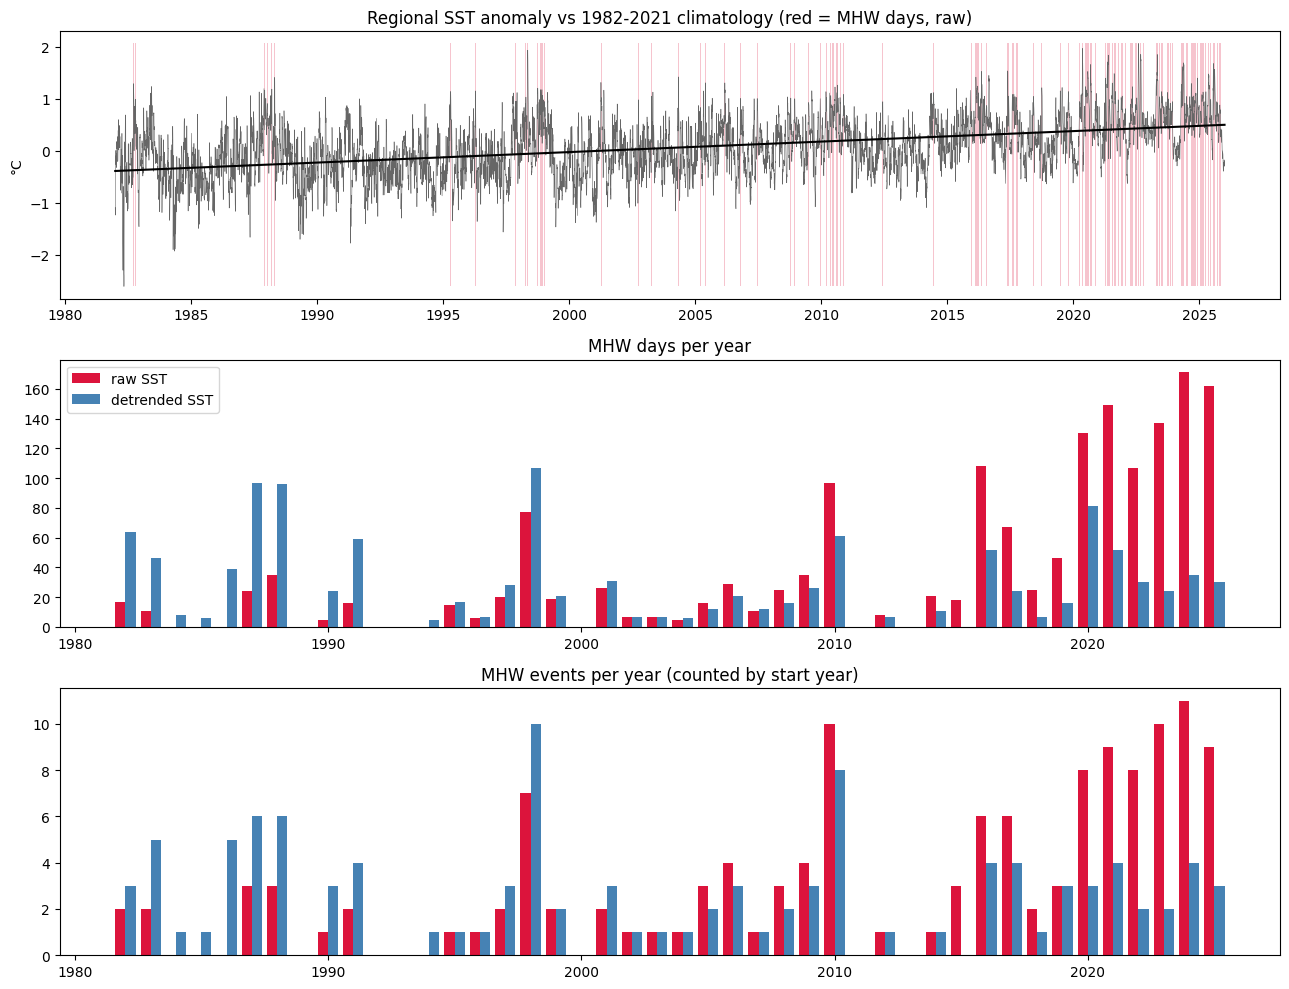

In [6]:
fig, ax = plt.subplots(3, 1, figsize=(13, 10))
a = d_raw["ssta"]
ax[0].plot(a.index, a, lw=0.4, color="0.4")
ax[0].fill_between(a.index, a.min(), a.max(), where=d_raw["mhw"] == 1, color="crimson", alpha=0.25, lw=0)
ax[0].plot(a.index, np.polyval(np.polyfit(t[ok], a.values[ok], 1), t), color="k")
ax[0].set_title(f"Regional SST anomaly vs {BASELINE[0]}-{BASELINE[1]} climatology (red = MHW days, raw)")
ax[0].set_ylabel("°C")
yrs = y_raw.index.to_numpy()
ax[1].bar(yrs - 0.2, y_raw["MHW days"], 0.4, label="raw SST", color="crimson")
ax[1].bar(yrs + 0.2, y_dt["MHW days"], 0.4, label="detrended SST", color="steelblue")
ax[1].set_title("MHW days per year"); ax[1].legend()
ax[2].bar(yrs - 0.2, y_raw["events (by start year)"], 0.4, color="crimson")
ax[2].bar(yrs + 0.2, y_dt["events (by start year)"], 0.4, color="steelblue")
ax[2].set_title("MHW events per year (counted by start year)")
plt.tight_layout()
plt.savefig(os.path.join(OUT_DIR, "mhw_check.png"), dpi=150)
plt.show()


## 7. Save clean outputs for EDA and the forecasting target.

In [7]:
out = pd.DataFrame({"sst": d_raw["sst"], "clim_mean": d_raw["seas"], "thresh90": d_raw["thresh"],
                    "ssta": d_raw["ssta"], "mhw_raw": d_raw["mhw"],
                    "sst_detrended": d_dt["sst"], "thresh90_detrended": d_dt["thresh"],
                    "mhw_detrended": d_dt["mhw"]}, index=dates)
out.index.name = "date"
out.to_csv(os.path.join(OUT_DIR, "mhw_daily_labels.csv"))
ev_raw.to_csv(os.path.join(OUT_DIR, "mhw_events_raw.csv"), index=False)
ev_dt.to_csv(os.path.join(OUT_DIR, "mhw_events_detrended.csv"), index=False)
table.to_csv(os.path.join(OUT_DIR, "mhw_yearly_stats.csv"))
print("Saved to", OUT_DIR)
print("\nTop 10 events (raw) by cumulative intensity:")
print(ev_raw.sort_values("cumulative_intensity_Cdays", ascending=False).head(10).to_string(index=False))


Saved to /content/drive/MyDrive/MHW/mhw_check

Top 10 events (raw) by cumulative intensity:
     start        end  duration_days  peak_date  max_intensity_C  mean_intensity_C  cumulative_intensity_Cdays
2020-06-24 2020-08-19             57 2020-07-29            1.528             1.135                      64.676
2024-04-07 2024-05-26             50 2024-05-16            1.693             1.249                      62.459
2016-02-03 2016-03-31             58 2016-02-20            1.417             1.003                      58.177
2023-04-09 2023-05-13             35 2023-05-01            1.854             1.310                      45.842
2025-01-16 2025-03-04             48 2025-02-23            1.131             0.881                      42.294
2021-05-02 2021-05-26             25 2021-05-21            1.842             1.523                      38.067
2021-08-09 2021-09-09             32 2021-08-15            1.486             1.085                      34.732
2022-07-26 2022-08-1

ocean cells: 805
median r = 0.73
cells with r >= 0.7: 62%
cells with r <  0.5: 0%


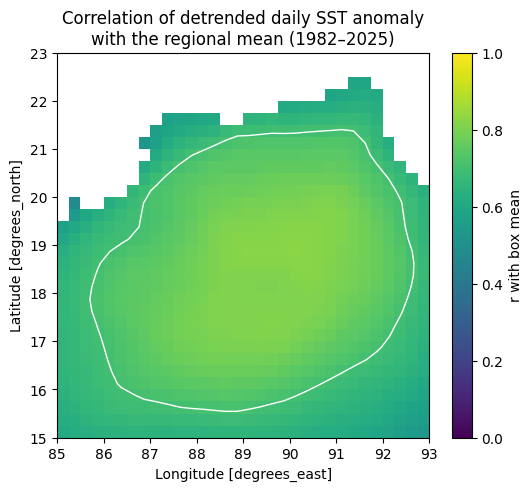

In [8]:
# Spatial coherence: how well does the box mean represent each grid cell?
cache = os.path.join(OUT_DIR, "oisst_box_grid.nc")
if os.path.exists(cache):
    grid = xr.open_dataarray(cache)
else:
    parts = []
    for f in files:
        ds = xr.open_dataset(f)
        da = ds["sst"]
        if "zlev" in da.dims:
            da = da.isel(zlev=0, drop=True)
        da = da.sortby("lat").sortby("lon").sel(lat=slice(*LAT), lon=slice(*LON)).load()
        parts.append(da)
        ds.close()
    grid = xr.concat(parts, "time")
    grid["time"] = grid.indexes["time"].floor("D")
    grid = grid.sel(time=slice("1982-01-01", "2025-12-31")).astype("float32")
    grid.to_netcdf(cache)

clim = grid.sel(time=slice("1982", "2021")).groupby("time.dayofyear").mean("time")
anom = (grid.groupby("time.dayofyear") - clim).drop_vars("dayofyear", errors="ignore")
fit = anom.polyfit("time", 1, skipna=True)                       # remove each cell's trend,
anom_dt = anom - xr.polyval(anom["time"], fit.polyfit_coefficients)  # so a shared trend can't inflate r
w = np.cos(np.deg2rad(anom_dt.lat))
box = anom_dt.weighted(w).mean(("lat", "lon"))
r = xr.corr(anom_dt, box, dim="time")

vals = r.values[~np.isnan(r.values)]
print(f"ocean cells: {vals.size}")
print(f"median r = {np.median(vals):.2f}")
print(f"cells with r >= 0.7: {100 * (vals >= 0.7).mean():.0f}%")
print(f"cells with r <  0.5: {100 * (vals < 0.5).mean():.0f}%")

fig, ax = plt.subplots(figsize=(6, 5))
r.plot(ax=ax, vmin=0, vmax=1, cmap="viridis", cbar_kwargs={"label": "r with box mean"})
r.plot.contour(ax=ax, levels=[0.7], colors="white", linewidths=1)
ax.set_title("Correlation of detrended daily SST anomaly\nwith the regional mean (1982–2025)")
plt.savefig(os.path.join(OUT_DIR, "spatial_coherence.png"), dpi=150, bbox_inches="tight")
plt.show()

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.5/9.5 MB 29.8 MB/s eta 0:00:00


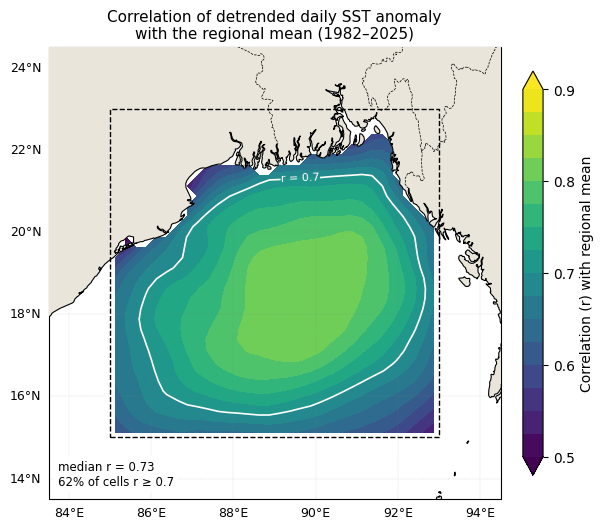

In [9]:
!pip -q install cartopy
import cartopy.crs as ccrs
import cartopy.feature as cfeature
import matplotlib.ticker as mticker

proj = ccrs.PlateCarree()
levels = np.arange(0.50, 0.901, 0.025)

fig = plt.figure(figsize=(7.2, 6.4))
ax = plt.axes(projection=proj)
ax.set_extent([83.5, 94.5, 13.5, 24.5], crs=proj)

# shaded correlation field
cf = ax.contourf(r.lon, r.lat, r, levels=levels, cmap="viridis",
                 extend="both", transform=proj, zorder=1)
# r = 0.7 contour
cs = ax.contour(r.lon, r.lat, r, levels=[0.7], colors="white",
                linewidths=1.2, transform=proj, zorder=2)
ax.clabel(cs, fmt="r = %.1f", fontsize=8, inline=True)

# land, coastline, country borders (drawn on top so coastal cells are cleanly masked)
ax.add_feature(cfeature.LAND.with_scale("10m"), facecolor="#e9e5da", zorder=3)
ax.add_feature(cfeature.COASTLINE.with_scale("10m"), linewidth=0.8, zorder=4)
ax.add_feature(cfeature.BORDERS.with_scale("10m"), linewidth=0.5, linestyle="--", zorder=4)

# study box outline
ax.plot([85, 93, 93, 85, 85], [15, 15, 23, 23, 15], color="black",
        linestyle="--", linewidth=1, transform=proj, zorder=5)

# gridlines with degree labels
gl = ax.gridlines(draw_labels=True, linewidth=0.3, color="gray", alpha=0.6, linestyle=":")
gl.top_labels = gl.right_labels = False
gl.xlocator = mticker.FixedLocator(range(84, 95, 2))
gl.ylocator = mticker.FixedLocator(range(14, 25, 2))
gl.xlabel_style = gl.ylabel_style = {"size": 9}

cb = plt.colorbar(cf, ax=ax, shrink=0.82, pad=0.04, ticks=np.arange(0.5, 0.91, 0.1))
cb.set_label("Correlation (r) with regional mean")

ax.text(0.02, 0.03,
        f"median r = {np.median(vals):.2f}\n{100 * (vals >= 0.7).mean():.0f}% of cells r ≥ 0.7",
        transform=ax.transAxes, fontsize=8.5, zorder=6,
        bbox=dict(facecolor="white", edgecolor="none", alpha=0.85, pad=3))
ax.set_title("Correlation of detrended daily SST anomaly\nwith the regional mean (1982–2025)", fontsize=11)

plt.savefig(os.path.join(OUT_DIR, "spatial_coherence_map.png"), dpi=300, bbox_inches="tight")
plt.savefig(os.path.join(OUT_DIR, "spatial_coherence_map.pdf"), bbox_inches="tight")
plt.show()